# Python Bytes domain reference authority

In [9]:
import bs4
import feedparser

## Get the RSS feed data as a dictionary

In [10]:
url = 'https://pythonbytes.fm/episodes/rss'
feed = feedparser.parse(url)
print(feed.get('feed').get('title'))

Python Bytes


In [11]:
print(f'Size of downloaded data: {len(str(feed)) / 1024 / 1024:,.1f} MB!')

Size of downloaded data: 2.3 MB!


## Extract the entries

In [12]:
entries = feed.get('entries')
print(f'Downloaded {len(entries):,} entries.')
# print(entries[0].get('description')[:300])

Downloaded 500 entries.


## Parse the HTML from the entry descriptions

The body is RSS but each entry's description is an HTML fragment so we must parse it that way.

In [13]:
all_links = []

for e in entries:
    desc = e.get('description')
    soup = bs4.BeautifulSoup('<html><body>' + desc + '</body></html>', 'html.parser')

    links = [a['href'] for a in soup.findAll('a')]
    links = [l.replace('www.', '') for l in links]
    links = [l.replace('do.co', 'digitalocean.com') for l in links]
    all_links.extend(links)


# unique_links = list(set(all_links))
all_links.sort()
# Yikes, bad links!
all_links = all_links[4:]

print(f'Parsed {len(all_links):,} links from all episodes.')

Parsed 15 links from all episodes.


C:\Users\Bruno Ferreira\AppData\Local\Temp\ipykernel_27912\1058402657.py:7: DeprecationWarning: Call to deprecated method findAll. (Replaced by find_all) -- Deprecated since version 4.0.0.
  links = [a['href'] for a in soup.findAll('a')]


## Extract domain names from the raw links.

In [14]:
from urllib.parse import urlparse

excluded = {'pythonbytes.fm', '', '#'}
domains = [urlparse(link).netloc for link in all_links if link not in excluded]
domains = [d for d in domains if d not in excluded]
print(f'First 10 domains are {domains[:10]} ...')

First 10 domains are ['discuss.python.org', 'getartcraft.com', 'lemire.me', 'llmfit.org', 'peps.python.org', 'pyfound.blogspot.com', 'satyrn.ai', 'satyrn.ai', 'speakerdeck.com', 'speakerdeck.com'] ...


## Count the domains

In [15]:
from collections import Counter

cn = Counter(domains)
common = cn.most_common()

top_25 = common[:25]
top_25

[('youtube.com', 3),
 ('satyrn.ai', 2),
 ('speakerdeck.com', 2),
 ('discuss.python.org', 1),
 ('getartcraft.com', 1),
 ('lemire.me', 1),
 ('llmfit.org', 1),
 ('peps.python.org', 1),
 ('pyfound.blogspot.com', 1),
 ('typesafe.ai', 1)]

## Summary of popular domains

Import and setup `matplotlib`

In [16]:
import matplotlib.pyplot as plt
import numpy as np

Generate a histogram of popular domains

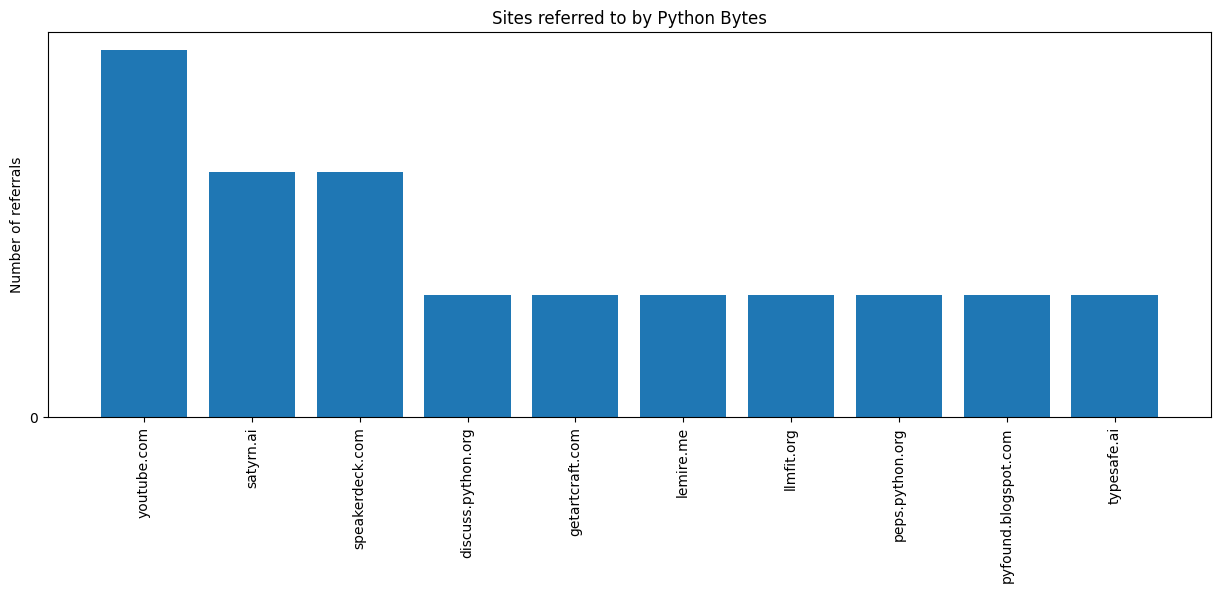

In [17]:
plt.rcParams['figure.figsize'] = (15, 5)

values = [t[1] for t in top_25]
value_bins = [t[0] for t in top_25]

ind = list(range(1, len(values) + 1))  # the x locations for the groups
width = 0.40  # the width of the bars: can also be len(x) sequence

# p1 = plt.bar(ind, menMeans, width)
p1 = plt.bar(ind, values, width * 2)

plt.ylabel('Number of referrals')
plt.title('Sites referred to by Python Bytes')
plt.xticks(ind, value_bins, rotation='vertical')
plt.yticks(np.arange(0, max(values), 50))
plt.width = 500